# Modelo CNN

Implementación de red neuronal CNN + **ResNet-50** optimizada con técnicas de data augmentation para estimar la Condición Corporal (BCS) en vacas a partir de recortes segmentados con máscaras SAM y realzados con CLAHE a forma de mejora.
La evaluación del modelo se realiza mediante **cross validation de 5 folds agrupando por animal** para garantizar la robustez del sistema.

### Fases del flujo de trabajo

1. **Preparación de datos:** Carga de recortes y asignación de folds por animal.
2. **Configuración del sistema:** Especificación técnica de los hiperparámetros y la arquitectura de la red.
3. **Entrenamiento:** Ejecución secuencial del entrenamiento y validación cruzada utilizando una receta estandarizada.
4. **Análisis de desempeño:** Evaluación de métricas y cumplimiento de objetivos del proyecto.

### Referencias:

CLAHE: https://www.geeksforgeeks.org/python/clahe-histogram-eqalization-opencv/

## Configuración

In [ ]:
from pathlib import Path

CARPETA_TRABAJO = '/content/drive/MyDrive/bcs_nube'
LOCAL = Path('/content')
VARIANTE = 'archivo_mascara_clahe'

# Red y validación
EXTRACTOR, PREENTRENADO, TAM_ENTRADA = 'resnet50.a1_in1k', True, 224
K_FOLDS, SEMILLA = 5, 42

# Receta de entrenamiento
ENTRENABLES   = ('layer4', 'fc')        # lo demás queda congelado
EPOCAS, LOTE  = 15, 32
LR_CAPAS, LR_CABEZA, WEIGHT_DECAY, DROPOUT = 1e-4, 1e-3, 1e-2, 0.2
AUGMENTATION  = dict(volteo=0.5, giro_grados=8, recorte_min=0.90, brillo=0.15, contraste=0.15)
VOLTEO_PRUEBA = True                    # al predecir: promedio de la foto y su espejo

# Objetivos del proyecto
INTERVALO, OBJ_MAE, OBJ_RMSE, OBJ_TOLERANCIA = (3.25, 3.50), 0.25, 0.35, 80.0
PASO, ESCALA, FLACA, BOOTSTRAP = 0.25, (1.0, 5.0), 2.75, 5000


## Preparar Colab: Drive, librerías y recortes

In [ ]:
import json, math, re, shutil, subprocess, sys, time, warnings, zipfile
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)
import numpy as np, pandas as pd, timm, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 220)

rutas = json.loads((Path(CARPETA_TRABAJO) / 'rutas.json').read_text(encoding='utf-8'))
zip_drive = Path(CARPETA_TRABAJO) / 'recortes_nube.zip'
assert zip_drive.exists(), 'No está recortes_nube.zip: corre primero la libreta 01'

if not (LOCAL / 'datos' / 'recortes' / 'recortes.csv').exists():
    shutil.copy2(zip_drive, LOCAL / 'recortes_nube.zip')
    with zipfile.ZipFile(LOCAL / 'recortes_nube.zip') as z:
        z.extractall(LOCAL)

DATOS = LOCAL / 'datos'
DISPOSITIVO = 'cuda' if torch.cuda.is_available() else 'cpu'
USAR_AMP = DISPOSITIVO == 'cuda'
print('Recortes en', DATOS / 'recortes', '· GPU:', torch.cuda.get_device_name(0) if USAR_AMP else 'NO GPU')

Mounted at /content/drive
Recortes en /content/datos/recortes · GPU: Tesla T4


##  Datos y folds

Recortes `ok` del rancho, sin laterales, con `usar = TRUE` en la tabla; `animal` y `ronda` salen de la tabla. Folds por animal: los animales ordenados se barajan una sola vez con la semilla 42 y se reparten en 5.

In [ ]:
def a_bool(v):
    return str(v).strip().lower() in {'true', '1', 'verdadero', 'si', 'sí', 'yes', 'x'}

def a_relativa(r):
    m = re.search(r'(?:^|/)(clean/.+)$', str(r).replace('\\', '/'))
    return m.group(1) if m else None

def limpiar_id(s):
    return s.astype(str).str.strip().str.replace(r'\.0$', '', regex=True)

rec = pd.read_csv(DATOS / 'recortes' / 'recortes.csv', dtype={'id_vaca': str, 'animal': str})
tab = pd.read_csv(rutas['RUTA_TABLA'])
tab['archivo_limpio'] = tab['archivo_limpio'].map(a_relativa)
tab = tab.dropna(subset=['archivo_limpio']).drop_duplicates('archivo_limpio')
tab['animal'], tab['usar_tabla'] = limpiar_id(tab['animal']), tab['usar'].map(a_bool)
rec = rec.drop(columns=['animal', 'ronda'], errors='ignore').merge(tab[['archivo_limpio', 'animal', 'ronda', 'usar_tabla']],
                                                                    on='archivo_limpio', how='left')
rec['id_vaca'] = limpiar_id(rec['id_vaca'])
excluidas = set()
if rutas.get('RUTA_EXCLUSIONES'):
    excluidas = set(limpiar_id(pd.read_csv(rutas['RUTA_EXCLUSIONES'], dtype=str)['id_vaca']))
datos = rec[(rec['estado'] == 'ok') & (rec['fuente'] == 'rancho') & (rec['vista'].fillna('') != 'lateral')
            & ~rec['id_vaca'].isin(excluidas) & (rec['usar_tabla'] == True)].reset_index(drop=True).copy()
datos['ronda'] = datos['ronda'].astype(int)

animales = sorted(datos['animal'].unique())
orden = np.random.default_rng(SEMILLA).permutation(animales)
FOLD = {a: i % K_FOLDS + 1 for i, a in enumerate(orden)}
datos['fold'] = datos['animal'].map(FOLD)

faltan = int((~datos[VARIANTE].map(lambda r: (DATOS / r).exists())).sum())
assert faltan == 0, 'Faltan recortes: vuelve a correr la 01'

print(f"Total de fotos cargadas: {len(datos)}")
print(f"Total de animales únicos: {datos['animal'].nunique()}")
print()
print(datos.groupby('fold').agg(animales=('animal', 'nunique'), sesiones=('id_vaca', 'nunique'), fotos=('id_vaca', 'size')).to_string())

Total de fotos cargadas: 604
Total de animales únicos: 80

      animales  sesiones  fotos
fold                           
1           16        19    148
2           16        19    109
3           16        19    112
4           16        20    132
5           16        16    103


## Configuración de la CNN

In [ ]:
config = pd.DataFrame([
    ('Entrada', f"{ {'archivo_mascara_clahe': 'recorte con máscara SAM + CLAHE', 'archivo_mascara': 'recorte con máscara SAM, sin CLAHE'}[VARIANTE] }, "
                f'{TAM_ENTRADA} × {TAM_ENTRADA}, normalizado con ImageNet'),
    ('Red base', f'{EXTRACTOR} preentrenada en ImageNet (23.5 M parámetros)'),
    ('Qué se entrena', ' + '.join(ENTRENABLES) + ' (≈ 15 M parámetros); stem y layer1–3 congelados, con BatchNorm fijo'),
    ('Cabeza', f'promedio global → dropout {DROPOUT} → lineal 2048 → 1; empieza en cero (arranca en el promedio)'),
    ('Objetivo', 'BCS estandarizado con las sesiones de entrenamiento (regresión)'),
    ('Pérdida', 'error cuadrático, peso por foto = 1 / fotos de su sesión'),
    ('Optimización', f'AdamW · lr {LR_CAPAS:g} ({ENTRENABLES[0]}) y {LR_CABEZA:g} (cabeza) · weight decay {WEIGHT_DECAY:g} · coseno · '
                     f'{EPOCAS} épocas · lote {LOTE} · precisión mixta en GPU'),
    ('Augmentation', f"espejo {AUGMENTATION['volteo']:.0%} · giro ±{AUGMENTATION['giro_grados']}° · acercamiento "
                     f"{AUGMENTATION['recorte_min']:.0%}–100 % · brillo y contraste ±{AUGMENTATION['brillo']:.0%}"),
    ('Validación', f'{K_FOLDS} folds por animal, semilla {SEMILLA}; receta fija, sin early stopping'),
    ('Predicción', 'promedio de la foto y su espejo; se redondea a 0.25 para % exacto y % a ±0.25'),
], columns=['', 'CNN afinada + augmentation']).set_index('')
display(config)

,CNN afinada + augmentation
,
Entrada,"recorte con máscara SAM + CLAHE, 224 × 224, no..."
Red base,resnet50.a1_in1k preentrenada en ImageNet (23....
Qué se entrena,layer4 + fc (≈ 15 M parámetros); stem y layer1...
Cabeza,promedio global → dropout 0.2 → lineal 2048 → ...
Objetivo,BCS estandarizado con las sesiones de entrenam...
Pérdida,"error cuadrático, peso por foto = 1 / fotos de..."
Optimización,AdamW · lr 0.0001 (layer4) y 0.001 (cabeza) · ...
Augmentation,espejo 50% · giro ±8° · acercamiento 90%–100 %...
Validación,"5 folds por animal, semilla 42; receta fija, s..."


## Recortes en memoria

In [ ]:
inicio = time.time()
IMGS = torch.from_numpy(np.stack([
    np.asarray(Image.open(DATOS / r).convert('RGB').resize((TAM_ENTRADA, TAM_ENTRADA), Image.BICUBIC))
    for r in datos[VARIANTE]])).permute(0, 3, 1, 2).contiguous()
print(f'Recortes {tuple(IMGS.shape)} en memoria ({IMGS.numel() / 1e6:.0f} MB) · {time.time() - inicio:.0f} s')

Recortes (604, 3, 224, 224) en memoria (91 MB) · 11 s


## Entrenamiento y validación cruzada

Solo `layer4` y la cabeza se entrenan; las capas congeladas quedan en modo evaluación. La cabeza empieza en cero (la red arranca prediciendo el promedio). Pérdida: error cuadrático ponderado por sesión sobre el BCS estandarizado. No se mide el error de prueba por época.

In [ ]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DISPOSITIVO).view(1, 3, 1, 1)
DESV  = torch.tensor([0.229, 0.224, 0.225], device=DISPOSITIVO).view(1, 3, 1, 1)

def aumentar(x, gen):
    B, A = x.shape[0], AUGMENTATION
    u = lambda: torch.rand(B, generator=gen)
    voltear = u() < A['volteo']
    x = torch.where(voltear.to(x.device).view(B, 1, 1, 1), torch.flip(x, dims=[3]), x)
    ang = (u() * 2 - 1) * A['giro_grados'] * math.pi / 180
    esc = A['recorte_min'] + u() * (1 - A['recorte_min'])
    tx, ty = (u() * 2 - 1) * (1 - esc), (u() * 2 - 1) * (1 - esc)
    theta = torch.stack([torch.stack([torch.cos(ang) * esc, -torch.sin(ang) * esc, tx], 1),
                         torch.stack([torch.sin(ang) * esc,  torch.cos(ang) * esc, ty], 1)], 1).to(x.device, x.dtype)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), mode='bilinear', padding_mode='border', align_corners=False)
    brillo = (1 + (u() * 2 - 1) * A['brillo']).to(x.device).view(B, 1, 1, 1)
    contraste = (1 + (u() * 2 - 1) * A['contraste']).to(x.device).view(B, 1, 1, 1)
    media = x.mean(dim=(1, 2, 3), keepdim=True)
    return (((x - media) * contraste + media) * brillo).clamp(0, 1)

def lote_normalizado(idx, gen=None):
    x = IMGS[idx].to(DISPOSITIVO, non_blocking=True).float() / 255
    if gen is not None:
        x = aumentar(x, gen)
    return (x - MEDIA) / DESV

def crear_modelo():
    modelo = timm.create_model(EXTRACTOR, pretrained=PREENTRENADO, num_classes=1, drop_rate=DROPOUT)
    torch.nn.init.zeros_(modelo.fc.weight); torch.nn.init.zeros_(modelo.fc.bias)
    for nombre, p in modelo.named_parameters():
        p.requires_grad = nombre.startswith(ENTRENABLES)
    return modelo.to(DISPOSITIVO)

def modo_entrenamiento(modelo):
    modelo.train()
    for nombre, m in modelo.named_children():
        if not nombre.startswith(ENTRENABLES):
            m.eval()

def entrenar(tr, semilla):
    torch.manual_seed(semilla)
    gen = torch.Generator().manual_seed(semilla)
    idx = torch.tensor(tr.index.to_numpy())
    sesiones = tr.groupby('id_vaca')['bcs'].first()
    mu, sd = float(sesiones.mean()), float(sesiones.std())
    z = torch.tensor(((tr['bcs'] - mu) / sd).to_numpy(), dtype=torch.float32, device=DISPOSITIVO)
    w = torch.tensor((1 / tr.groupby('id_vaca')['id_vaca'].transform('size')).to_numpy(), dtype=torch.float32, device=DISPOSITIVO)
    modelo = crear_modelo()
    capas = [p for n, p in modelo.named_parameters() if p.requires_grad and not n.startswith('fc')]
    opt = torch.optim.AdamW([{'params': capas, 'lr': LR_CAPAS}, {'params': modelo.fc.parameters(), 'lr': LR_CABEZA}], weight_decay=WEIGHT_DECAY)
    pasos = len(idx) // LOTE
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS * pasos)
    escalador = torch.amp.GradScaler('cuda', enabled=USAR_AMP)
    historial = []
    for epoca in range(EPOCAS):
        modo_entrenamiento(modelo)
        orden_e = torch.randperm(len(idx), generator=gen)
        perdidas = []
        for i in range(pasos):
            pos = orden_e[i * LOTE:(i + 1) * LOTE]
            x = lote_normalizado(idx[pos], gen)
            with torch.autocast(device_type=DISPOSITIVO, dtype=torch.float16, enabled=USAR_AMP):
                salida = modelo(x).squeeze(1)
            wb, zb = w[pos.to(DISPOSITIVO)], z[pos.to(DISPOSITIVO)]
            perdida = (wb * (salida.float() - zb) ** 2).sum() / wb.sum()
            opt.zero_grad(set_to_none=True)
            escalador.scale(perdida).backward()
            escalador.step(opt); escalador.update(); sched.step()
            perdidas.append(perdida.item())
        historial.append(float(np.mean(perdidas)))
    return modelo, mu, sd, historial

@torch.no_grad()
def predecir(modelo, idx, mu, sd, lote=64):
    modelo.eval()
    salida = []
    for i in range(0, len(idx), lote):
        x = lote_normalizado(idx[i:i + lote])
        with torch.autocast(device_type=DISPOSITIVO, dtype=torch.float16, enabled=USAR_AMP):
            o = modelo(x).squeeze(1).float()
            if VOLTEO_PRUEBA:
                o = (o + modelo(torch.flip(x, dims=[3])).squeeze(1).float()) / 2
        salida.append(o.cpu())
    return mu + sd * torch.cat(salida).numpy()

datos['cnn'] = np.nan
por_vuelta, historiales, inicio = [], [], time.time()
for k in range(1, K_FOLDS + 1):
    tr, te = datos[datos['fold'] != k], datos[datos['fold'] == k]
    modelo, mu, sd, hist = entrenar(tr, SEMILLA + k)
    datos.loc[te.index, 'cnn'] = predecir(modelo, torch.tensor(te.index.to_numpy()), mu, sd)
    p_tr = predecir(modelo, torch.tensor(tr.index.to_numpy()), mu, sd)
    por_vuelta.append({'vuelta': k, 'animales_entrenamiento': tr['animal'].nunique(), 'fotos_entrenamiento': len(tr),
                       'mae_entrenamiento': float(np.abs(p_tr - tr['bcs']).mean()),
                       'mae_prueba': float(np.abs(datos.loc[te.index, 'cnn'] - te['bcs']).mean())})
    historiales.append(hist)
    print(f"vuelta {k}: MAE prueba {por_vuelta[-1]['mae_prueba']:.3f} · entrenamiento {por_vuelta[-1]['mae_entrenamiento']:.3f} · "
          f"{time.time() - inicio:.0f} s")
    del modelo
    if USAR_AMP:
        torch.cuda.empty_cache()
por_vuelta = pd.DataFrame(por_vuelta).set_index('vuelta')
display(por_vuelta.round(3))

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

vuelta 1: MAE prueba 0.283 · entrenamiento 0.157 · 28 s
vuelta 2: MAE prueba 0.272 · entrenamiento 0.164 · 45 s
vuelta 3: MAE prueba 0.366 · entrenamiento 0.155 · 62 s
vuelta 4: MAE prueba 0.306 · entrenamiento 0.156 · 78 s
vuelta 5: MAE prueba 0.277 · entrenamiento 0.159 · 95 s


,animales_entrenamiento,fotos_entrenamiento,mae_entrenamiento,mae_prueba
vuelta,,,,
1,64,456,0.157,0.283
2,64,495,0.164,0.272
3,64,492,0.155,0.366
4,64,472,0.156,0.306
5,64,501,0.159,0.277


## Curva de aprendizaje y MAE

- **Izquierda:** pérdida de entrenamiento por época en cada vuelta (1 = predecir siempre el promedio).
- **Derecha:** MAE de entrenamiento contra prueba por vuelta. Hay señal de sobreajuste (*overfitting*): la barra de entrenamiento queda muy por debajo de la de prueba, es decir, la red memoriza a las vacas que ve.

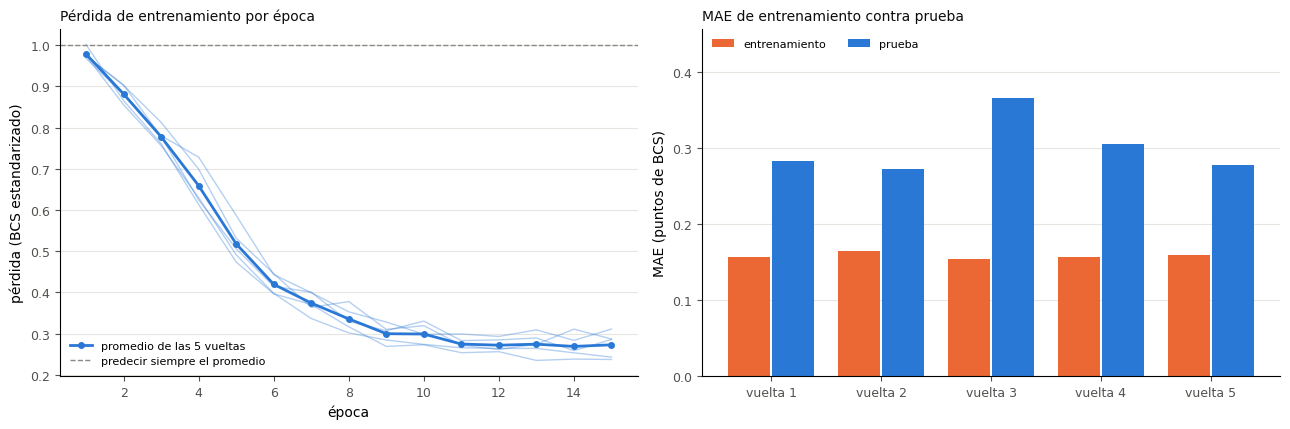

In [ ]:
AZUL, NARANJA, GRIS, VERDE = '#2a78d6', '#eb6834', '#8a8984', '#1baf7a'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
def estilo(ax, titulo):
    ax.set_title(titulo, fontsize=10, color=TINTA, loc='left')
    ax.grid(axis='y', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    ax.tick_params(colors=TINTA_2, labelsize=9)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
ep = np.arange(1, EPOCAS + 1)
for h in historiales:
    axs[0].plot(ep, h, color=AZUL, lw=1, alpha=0.35)
axs[0].plot(ep, np.mean(historiales, axis=0), color=AZUL, lw=2, marker='o', ms=4, label='promedio de las 5 vueltas')
axs[0].axhline(1, color=GRIS, ls='--', lw=1, label='predecir siempre el promedio')
axs[0].set(xlabel='época', ylabel='pérdida (BCS estandarizado)'); axs[0].legend(fontsize=8, frameon=False)
axs[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
estilo(axs[0], 'Pérdida de entrenamiento por época')
xs = np.arange(K_FOLDS)
axs[1].bar(xs - 0.2, por_vuelta['mae_entrenamiento'], 0.38, color=NARANJA, label='entrenamiento')
axs[1].bar(xs + 0.2, por_vuelta['mae_prueba'], 0.38, color=AZUL, label='prueba')
axs[1].set(xticks=xs, xticklabels=[f'vuelta {k}' for k in por_vuelta.index], ylabel='MAE (puntos de BCS)')
axs[1].legend(fontsize=8, frameon=False, ncol=2, loc='upper left'); axs[1].set_ylim(0, por_vuelta[['mae_entrenamiento', 'mae_prueba']].values.max() * 1.25)
estilo(axs[1], 'MAE de entrenamiento contra prueba')
plt.tight_layout(); plt.show()

## Resultados

* **Real contra predicho por vaca** (promedio de las fotos de cada sesión). Cada punto está exactamente en su BCS real (sin desplazamiento).
* **Error medio por nivel de BCS:** positivo = sobreestima. Si las flacas salen positivas y las gordas negativas, la red **comprime** las predicciones hacia el centro.

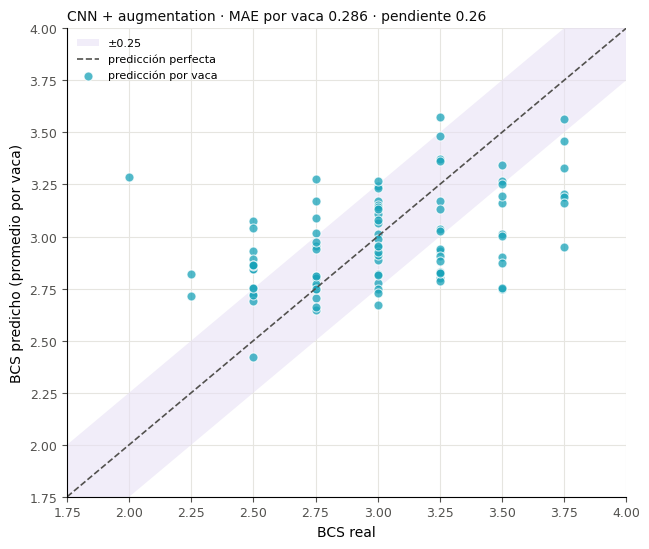

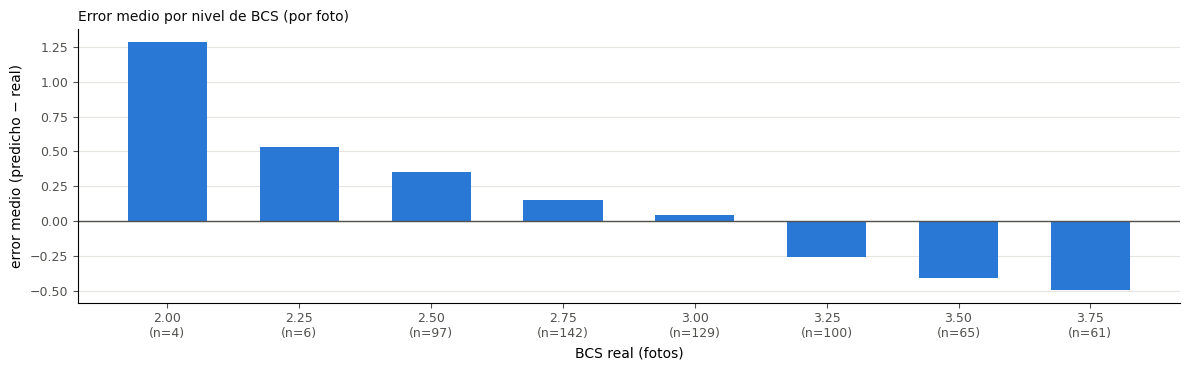

In [ ]:
redondear = lambda x: np.clip(np.round(np.asarray(x, float) / PASO) * PASO, *ESCALA)
def por_sesion(df):
    return df.groupby('id_vaca').agg(animal=('animal', 'first'), bcs=('bcs', 'first'), cnn=('cnn', 'mean'))
ses = por_sesion(datos)

lims = [min(ses['bcs'].min(), ses['cnn'].min()) - 0.25, max(ses['bcs'].max(), ses['cnn'].max()) + 0.25]
fig, ax = plt.subplots(figsize=(6.6, 5.6))
COLOR_BANDA, COLOR_PUNTOS = '#e8e1f5', '#17a2b8'
ax.fill_between(lims, [l - 0.25 for l in lims], [l + 0.25 for l in lims], color=COLOR_BANDA, alpha=0.6, lw=0, label='±0.25')
ax.plot(lims, lims, color=TINTA_2, lw=1.2, ls='--', label='predicción perfecta')
ax.scatter(ses['bcs'], ses['cnn'], s=42, color=COLOR_PUNTOS, alpha=0.75, edgecolor='white', linewidth=0.8, label='predicción por vaca')
pend = np.polyfit(ses['bcs'], ses['cnn'], 1)[0]
ax.set(xlim=lims, ylim=lims, xlabel='BCS real', ylabel='BCS predicho (promedio por vaca)')
estilo(ax, f"CNN + augmentation · MAE por vaca {np.abs(ses['cnn'] - ses['bcs']).mean():.3f} · pendiente {pend:.2f}")
ax.grid(color='#e6e5e0', lw=0.8); ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

niveles = sorted(datos['bcs'].unique())
err = datos.assign(e=datos['cnn'] - datos['bcs']).groupby('bcs')['e'].mean()
n_fotos = datos.groupby('bcs').size()
fig, ax = plt.subplots(figsize=(12, 3.8))
xs = np.arange(len(niveles))
ax.bar(xs, err.reindex(niveles), 0.6, color=AZUL)
ax.axhline(0, color=TINTA_2, lw=1)
ax.set(xticks=xs, xticklabels=[f'{b:.2f}\n(n={n_fotos[b]})' for b in niveles], xlabel='BCS real (fotos)', ylabel='error medio (predicho − real)')
estilo(ax, 'Error medio por nivel de BCS (por foto)')
plt.tight_layout(); plt.show()

## Métricas

Por foto y por vaca, en todo el rango y en 3.25–3.50.
**MAE_IC95**: intervalo de confianza del MAE por bootstrap por animal (se remuestrean animales completos, no fotos).
**AUC flacas** (por sesión, exploratorio): qué tan bien ordena la red a las vacas con BCS ≤ 2.75 por encima de las demás.

In [ ]:
def metricas(df, col='cnn'):
    y, p = df['bcs'].to_numpy(float), df[col].to_numpy(float)
    e, r = p - y, redondear(p)
    varia = len(set(y)) > 1 and np.std(p) > 0
    return {'n': len(y), 'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'exacto_%': 100 * np.mean(r == y),
            'a_0.25_%': 100 * np.mean(np.abs(r - y) <= 0.25 + 1e-9), 'a_0.5_%': 100 * np.mean(np.abs(r - y) <= 0.5 + 1e-9),
            'spearman': spearmanr(y, p).correlation if varia else np.nan, 'pendiente': np.polyfit(y, p, 1)[0] if varia else np.nan}

def ic_mae(df, col='cnn'):
    g = df.assign(e=(df[col] - df['bcs']).abs(), n=1).groupby('animal')[['e', 'n']].sum()
    idx = np.random.default_rng(SEMILLA).integers(0, len(g), size=(BOOTSTRAP, len(g)))
    m = g['e'].to_numpy()[idx].sum(1) / g['n'].to_numpy()[idx].sum(1)
    return f'{np.percentile(m, 2.5):.3f} a {np.percentile(m, 97.5):.3f}'

filas_t = []
for nivel in ['foto', 'vaca']:
    for rango in ['todo', f'{INTERVALO[0]}–{INTERVALO[1]}']:
        base = datos if rango == 'todo' else datos[datos['bcs'].between(*INTERVALO)]
        df = base if nivel == 'foto' else por_sesion(base)
        filas_t.append({'nivel': nivel, 'rango': rango, **metricas(df), 'MAE_IC95': ic_mae(df)})
display(pd.DataFrame(filas_t).round(3))
flaca = ses['bcs'] <= FLACA
print(f'AUC flacas (BCS ≤ {FLACA}, {int(flaca.sum())} de {len(ses)} sesiones): {roc_auc_score(flaca, -ses["cnn"]):.2f}')
print(f"Rango de las predicciones por vaca: {ses['cnn'].min():.2f}–{ses['cnn'].max():.2f} (real: {ses['bcs'].min():.2f}–{ses['bcs'].max():.2f})")

,nivel,rango,n,MAE,RMSE,exacto_%,a_0.25_%,a_0.5_%,spearman,pendiente,MAE_IC95
0,foto,todo,604,0.300,0.374,25.828,67.384,91.556,0.396,0.259,0.255 a 0.347
1,foto,3.25–3.5,165,0.348,0.401,14.545,55.152,90.303,0.217,0.411,0.289 a 0.421
2,vaca,todo,93,0.286,0.357,26.882,73.118,94.624,0.458,0.262,0.246 a 0.330
3,vaca,3.25–3.5,28,0.355,0.397,14.286,60.714,89.286,-0.005,-0.024,0.290 a 0.425


AUC flacas (BCS ≤ 2.75, 35 de 93 sesiones): 0.75
Rango de las predicciones por vaca: 2.42–3.57 (real: 2.00–3.75)


##  Objetivos del proyecto
Criterios de éxito, en las fotos cuyo BCS **real** está entre 3.25 y 3.50: **MAE ≤ 0.25**, **RMSE ≤ 0.35** y **≥ 80 % a ±0.25** (con la predicción redondeada a 0.25). Se muestran por foto (como los definió el equipo) y por vaca, con lo que falta para cada meta.

In [ ]:
filas_o = []
base = datos[datos['bcs'].between(*INTERVALO)]
for nivel, df in [('foto', base), ('vaca', por_sesion(base))]:
    m = metricas(df)
    cumple = {'MAE': m['MAE'] <= OBJ_MAE + 1e-9, 'RMSE': m['RMSE'] <= OBJ_RMSE + 1e-9, 'tol': m['a_0.25_%'] >= OBJ_TOLERANCIA - 1e-9}
    filas_o.append({'nivel': nivel, 'n': m['n'],
                    'MAE': m['MAE'], f'MAE ≤ {OBJ_MAE}': '✓' if cumple['MAE'] else f"✗ (sobra {m['MAE'] - OBJ_MAE:.3f})",
                    'RMSE': m['RMSE'], f'RMSE ≤ {OBJ_RMSE}': '✓' if cumple['RMSE'] else f"✗ (sobra {m['RMSE'] - OBJ_RMSE:.3f})",
                    '±0.25 %': m['a_0.25_%'], f'±0.25 ≥ {OBJ_TOLERANCIA:.0f} %': '✓' if cumple['tol'] else f"✗ (faltan {OBJ_TOLERANCIA - m['a_0.25_%']:.1f} pp)",
                    'cumple los tres': all(cumple.values())})
tabla_obj = pd.DataFrame(filas_o).set_index('nivel')
display(tabla_obj.round(3))
for nivel, f in tabla_obj.iterrows():
    print(f"{nivel}: {'CUMPLE los tres criterios' if f['cumple los tres'] else 'NO cumple'} "
          f"(MAE {f['MAE']:.3f}, RMSE {f['RMSE']:.3f}, ±0.25 {f['±0.25 %']:.1f} %; {int(f['n'])} {'fotos' if nivel == 'foto' else 'sesiones'})")

,n,MAE,MAE ≤ 0.25,RMSE,RMSE ≤ 0.35,±0.25 %,±0.25 ≥ 80 %,cumple los tres
nivel,,,,,,,,
foto,165,0.348,✗ (sobra 0.098),0.401,✗ (sobra 0.051),55.152,✗ (faltan 24.8 pp),False
vaca,28,0.355,✗ (sobra 0.105),0.397,✗ (sobra 0.047),60.714,✗ (faltan 19.3 pp),False


foto: NO cumple (MAE 0.348, RMSE 0.401, ±0.25 55.2 %; 165 fotos)
vaca: NO cumple (MAE 0.355, RMSE 0.397, ±0.25 60.7 %; 28 sesiones)
